<a href="https://colab.research.google.com/github/bhuvanarangaiah/03MAIR-Algoritmos-de-Optimizacion-2026/blob/main/SEMINARIO/Bhuvana-Juan-TrabajoPractico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Algoritmos de optimización - Seminario
Nombre y Apellidos:   <br>
- Bhuvana Rangaiah Cheemala Marri
- Juan Pablo Salas Suarez

Url: https://github.com/bhuvanarangaiah/03MAIR-Algoritmos-de-Optimizacion-2026/tree/main/SEMINARIO<br>
Problema:
> 1. Sesiones de doblaje <br>

Descripción del problema:

- Se precisa coordinar el doblaje de una película. Los actores del doblaje deben coincidir en las
tomas en las que sus personajes aparecen juntos en las diferentes tomas. Los actores de
doblaje cobran todos la misma cantidad por cada día que deben desplazarse hasta el estudio de
grabación independientemente del número de tomas que se graben. No es posible grabar más
de 6 tomas por día. El objetivo es planificar las sesiones por día de manera que el gasto por los
servicios de los actores de doblaje sea el menor posible.<br>
    - Los datos son:<br>
        - Número de actores: 10<br>
        - Número de tomas : 30<br><br>

    Actores/Tomas : https://bit.ly/36D8IuK <br>
    - 1 indica que el actor participa en la toma
    - 0 en caso contrario

....

(*) La respuesta es obligatoria                                        

### Carga de Datos:

In [18]:
# ============================================================
# CARGA DE DATOS - Problema 1: Sesiones de doblaje
# ============================================================

""" 
Datos: 30 tomas x 10 actores. M[t][a] = 1 si el actor a participa en la toma t, 0 en caso contrario.
Se cargan los datos directamente a continuación para que el notebook no depende de ficheros externos.
"""

MAX_TOMAS_POR_DIA = 6

# Matriz de participacion (formato de entrada, tal cual la hoja)
matriz = [
    [1,1,1,1,1,0,0,0,0,0],  # toma 1
    [0,0,1,1,1,0,0,0,0,0],  # toma 2
    [0,1,0,0,1,0,1,0,0,0],  # toma 3
    [1,1,0,0,0,0,1,1,0,0],  # toma 4
    [0,1,0,1,0,0,0,1,0,0],  # toma 5
    [1,1,0,1,1,0,0,0,0,0],  # toma 6
    [1,1,0,1,1,0,0,0,0,0],  # toma 7
    [1,1,0,0,0,1,0,0,0,0],  # toma 8
    [1,1,0,1,0,0,0,0,0,0],  # toma 9
    [1,1,0,0,0,1,0,0,1,0],  # toma 10
    [1,1,1,0,1,0,0,1,0,0],  # toma 11
    [1,1,1,1,0,1,0,0,0,0],  # toma 12
    [1,0,0,1,1,0,0,0,0,0],  # toma 13
    [1,0,1,0,0,1,0,0,0,0],  # toma 14
    [1,1,0,0,0,0,1,0,0,0],  # toma 15
    [0,0,0,1,0,0,0,0,0,1],  # toma 16
    [1,0,1,0,0,0,0,0,0,0],  # toma 17
    [0,0,1,0,0,1,0,0,0,0],  # toma 18
    [1,0,1,0,0,0,0,0,0,0],  # toma 19
    [1,0,1,1,1,0,0,0,0,0],  # toma 20
    [0,0,0,0,0,1,0,1,0,0],  # toma 21
    [1,1,1,1,0,0,0,0,0,0],  # toma 22
    [1,0,1,0,0,0,0,0,0,0],  # toma 23
    [0,0,1,0,0,1,0,0,0,0],  # toma 24
    [1,1,0,1,0,0,0,0,0,1],  # toma 25
    [1,0,1,0,1,0,0,0,1,0],  # toma 26
    [0,0,0,1,1,0,0,0,0,0],  # toma 27
    [1,0,0,1,0,0,0,0,0,0],  # toma 28
    [1,0,0,0,1,1,0,0,0,0],  # toma 29
    [1,0,0,1,0,0,0,0,0,0],  # toma 30
]

N_ACTORES = len(matriz[0])       # 10

# Transformamos la matriz a lista de conjuntos de actores
tomas_completo = []
for fila in matriz:
    actores_de_toma = set()
    for a in range(N_ACTORES):
        if fila[a] == 1:
            actores_de_toma.add(a + 1)
    tomas_completo.append(actores_de_toma)

# AJUSTE para probar el modelo: Seleccionamos solo las primeras N tomas dado que como se indicó en los puntos anteriores no es posible probar con 30
NUM_TOMAS_PRUEBA = 10 

tomas_prueba = tomas_completo[:NUM_TOMAS_PRUEBA]
tomas = [ {a+1 for a in range(N_ACTORES) if fila[a]==1} for fila in matriz ]

N_TOMAS = len(tomas_prueba)

print('Actores por cada toma: ', tomas)

Actores por cada toma:  [{1, 2, 3, 4, 5}, {3, 4, 5}, {2, 5, 7}, {8, 1, 2, 7}, {8, 2, 4}, {1, 2, 4, 5}, {1, 2, 4, 5}, {1, 2, 6}, {1, 2, 4}, {1, 2, 6, 9}, {1, 2, 3, 5, 8}, {1, 2, 3, 4, 6}, {1, 4, 5}, {1, 3, 6}, {1, 2, 7}, {10, 4}, {1, 3}, {3, 6}, {1, 3}, {1, 3, 4, 5}, {8, 6}, {1, 2, 3, 4}, {1, 3}, {3, 6}, {1, 2, 10, 4}, {1, 3, 5, 9}, {4, 5}, {1, 4}, {1, 5, 6}, {1, 4}]


### (*)¿Cuantas posibilidades hay sin tener en cuenta las restricciones?<br>

### ¿Cuantas posibilidades hay teniendo en cuenta todas las restricciones.

Respuesta

**Sin restricciones.** El coste solo depende de *qué tomas se agrupan* en un mismo día, no del nombre del día. Cada plan es por tanto una **partición** de las 30 tomas en grupos, y su número es el **número de Bell** B(30) ≈ 8.47·10²³. (Si los días estuvieran etiquetados y hubiera X días disponibles serían X³⁰ asignaciones.)

**Con restricciones (≤ 6 tomas por día).** Solo valen las particiones con grupos de **como máximo 6 tomas** (5 días de 6, pero también 6 días de 5, etc.). Se cuentan con una recurrencia: la toma de menor índice va en un grupo de tamaño g (1…6); se eligen sus g−1 compañeras entre las m−1 restantes y el resto se reparte de f(m−g) formas:

$$f(m)=\sum_{g=1}^{\min(m,6)}\binom{m-1}{g-1}f(m-g),\qquad f(0)=1 \;\Rightarrow\; f(30)\approx 7.264\cdot10^{23}$$

Contar solo "5 días × 6 tomas", 30!/((6!)⁵·5!) ≈ 1.14·10¹⁶, sería un error: es un subconjunto diminuto de los planes válidos.

In [19]:
# ============================================================
# NUMERO DE POSIBILIDADES - Problema 1: Sesiones de doblaje
# ============================================================
import math
from functools import lru_cache

N = 30  # tomas

# SIN restricciones: numero de Bell B(n) (triangulo de Bell)
def bell(n):
    fila = [1]
    for _ in range(n):
        siguiente = [fila[-1]]
        for x in fila:
            siguiente.append(siguiente[-1] + x)
        fila = siguiente
    return fila[0]

# CON restricciones: particiones en grupos de <= k tomas
#   f(m) = sum_{g=1..min(m,k)} C(m-1, g-1) * f(m-g),  f(0) = 1
@lru_cache(maxsize=None)
def particiones_acotadas(m, k=MAX_TOMAS_POR_DIA):
    if m == 0:
        return 1
    return sum(math.comb(m - 1, g - 1) * particiones_acotadas(m - g, k)
               for g in range(1, min(m, k) + 1))

print(f"SIN restricciones: B(30) = {bell(N):.3e}")
print(f"CON restricciones: f(30) = {particiones_acotadas(N):,}  ({particiones_acotadas(N):.3e})")
print(f"(solo 5 dias x 6 tomas seria {math.factorial(N)//(math.factorial(6)**5*math.factorial(5)):.3e}, un subconjunto minimo)")

# Comprobacion de la recurrencia: enumeracion directa para n pequeño y k = n -> Bell
def contar_enumerando(n, k):
    def rec(i, tam):
        if i == n: return 1
        total = 0
        for j in range(len(tam)):
            if tam[j] < k:
                tam[j] += 1; total += rec(i + 1, tam); tam[j] -= 1
        tam.append(1); total += rec(i + 1, tam); tam.pop()
        return total
    return rec(0, [])

assert all(contar_enumerando(n, 6) == particiones_acotadas(n, 6) for n in range(1, 11))
assert particiones_acotadas(N, N) == bell(N)
print("Recurrencia verificada (enumeracion n<=10 y caso k=n = Bell).")

SIN restricciones: B(30) = 8.467e+23
CON restricciones: f(30) = 726,391,948,970,868,949,621,309  (7.264e+23)
(solo 5 dias x 6 tomas seria 1.142e+16, un subconjunto minimo)
Recurrencia verificada (enumeracion n<=10 y caso k=n = Bell).


### Modelo para el espacio de soluciones<br>
### (*) ¿Cual es la estructura de datos que mejor se adapta al problema? Argumentalo.(Es posible que hayas elegido una al principio y veas la necesidad de cambiar, arguentalo)


**Respuesta**

**A) Entrada.** La matriz 30×10 de 0/1 solo sirve para cargar los datos. Después convertimos cada toma en un **conjunto (set) de actores**: el coste de un día es el tamaño de la **unión** de los sets de sus tomas, y con la matriz habría que recorrer columnas una y otra vez. Empezamos con la matriz y cambiamos a sets por esa razón.

**B) Solución.** Una **lista de días**, y cada día una **lista de índices de toma**, p. ej. `[[0,1,2],[3,4,5],...]`. Permite mover o intercambiar tomas entre días y comprobar el límite de 6 con `len(dia)`.

In [20]:
# ============================================================
# ESTRUCTURA DE DATOS - demostracion
# ============================================================
# A) Entrada: matriz (carga) -> lista de SETS de actores por toma 

ejemplo_matriz = matriz[0]                      # fila de la toma 1
ejemplo_set    = tomas[0]                        # {1,2,3,4,5}

print("Toma 1 como fila de matriz :", ejemplo_matriz)
print("Toma 1 como set de actores :", sorted(ejemplo_set))

# Operacion clave (coste de un dia) = tamaño de la UNION de sets

dia_ejemplo = [0, 1, 5]                           # hago las tomas 1, 2, 6

union_actores = set().union(*[tomas[t] for t in dia_ejemplo])
print("\nDia grabando las tomas 1,2,6 -> necesito a los actores:", sorted(union_actores),
      "-> coste dia (suponiendo $1 actor/día= $", len(union_actores))

# B) Solucion: lista de dias, cada dia una lista de indices de toma
solucion_ejemplo = [[0,1,2,3,4,5],[6,7,8,9,10,11]]
print("\nSolucion (lista de dias -> tomas):", solucion_ejemplo)
print("Tomas en el dia 1:", len(solucion_ejemplo[0]), "(<= 6 OK)")


Toma 1 como fila de matriz : [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
Toma 1 como set de actores : [1, 2, 3, 4, 5]

Dia grabando las tomas 1,2,6 -> necesito a los actores: [1, 2, 3, 4, 5] -> coste dia (suponiendo $1 actor/día= $ 5

Solucion (lista de dias -> tomas): [[0, 1, 2, 3, 4, 5], [6, 7, 8, 9, 10, 11]]
Tomas en el dia 1: 6 (<= 6 OK)


### Según el modelo para el espacio de soluciones<br>
### (*)¿Cual es la función objetivo?

### (*)¿Es un problema de maximización o minimización?

Respuesta:

Estamos ante un problema de **minimización**. La función objetivo es reducir al máximo el gasto total en sueldos/jornadas de los actores de doblaje. Cada actor cobra una tarifa fija por día, sin importar cuántas tomas haga. Por lo tanto, el costo de un día va a depender del número de actores distintos que participan en las tomas de ese día. Si agrupamos tomas que comparten actores en el mismo día, reducimos el número de días en que esos actores deben desplazarse.

De forma matemática definimos la siguiente variable binaria de decisión: 

$y_{i,k} \in \{0, 1\}$: Indica si el actor $i$ tiene que ir a grabar el día $k$.

$y_{i,k} = 1$ si el actor $i$ asiste a grabar el día $k$.

$y_{i,k} = 0$ si el actor $i$ no asiste el día $k$.

Donde: 

$i \in \{1, 2, \dots, 10\}$ (los 10 actores).

$k \in \{1, 2, \dots, D\}$ (los días de grabación, donde $D$ es entre 5 y 30 días).

Como todos los actores cobran exactamente la misma tarifa por día de desplazamiento ($C$), la función objetivo formal se expresa así:$$\min \quad Z = C \cdot \sum_{i=1}^{10} \sum_{k=1}^{D} y_{i,k}$$

**Peor escenario posible:** Que los actores tengan que ir muchos días a grabar pocas tomas cada uno (por ejemplo, sumar 35 convocatorias de actor a lo largo del rodaje).

**Escenario óptimo (lo que busca la función):** Agrupar las 30 tomas de tal forma que los actores compartan días tanto como sea posible, reduciendo la suma total de asistencias (por ejemplo, lograr realizar todo con solo 18 convocatorias de actor en total).

### Diseña un algoritmo para resolver el problema por fuerza bruta

Respuesta

In [21]:
# --- Verificaciones rapidas ---
print("Nº tomas de prueba   :", N_TOMAS)
print("Nº actores :", N_ACTORES)
print()
print("Ejemplos (toma -> actores):")
for t in [0,1,3]:
    print(f"  toma {t+1:2d}: {sorted(tomas[t])}")
print()
# Cuantas tomas hace cada actor
por_actor = {}
for a in range(1, N_ACTORES+1):
    contador = 0
    for f in matriz:
        if f[a-1]==1:
            contador +=1
    por_actor[a]= contador
    
print("Tomas por actor (si se tomaran las 30 tomas):", por_actor)


def calcular_coste(dias): #funcion para calcular el costo total
    """
    Recibe la estructura de 'dias' y suma cuántos actores ÚNICOS van cada día.
    Si el Actor 1 graba 3 tomas en el Día 1, solo se le cuenta 1 asistencia.
    """
    coste_total = 0
    
    for dia in dias:
        # Usamos un conjunto para almacenar los actores que asisten en este día sin repetir
        actores_del_dia = set()
        
        # Cada 'dia' contiene una lista de tomas asignadas
        for toma_actores in dia:
            for actor in toma_actores:
                actores_del_dia.add(actor)
                
        # La cantidad de actores únicos asistiendo hoy es la longitud del conjunto
        coste_total += len(actores_del_dia)
        
    return coste_total


# ALGORITMO RECURSIVO DE FUERZA BRUTA (BACKTRACKING)

def buscar_optimo(toma_idx=0, dias=()):
    """
    Evalúa todas las combinaciones posibles asignando una toma a la vez.
    - toma_idx: Número de la toma actual que estamos intentando colocar (0 a 29).
    - dias: Estado actual de la agenda de días con las tomas asignadas.
    """
    
    # CASO BASE:  si ya se han asigado todas las tomas se calcula el costo    
    if toma_idx == N_TOMAS:
        coste = calcular_coste(dias)
        return coste, dias

    # PASO RECURSIVO: Obtenemos el conjunto de actores de la toma actual
    actores_toma_actual = tomas[toma_idx]
    
    # se guardan los resultados de explorar cada camino posible
    opciones = []

    # --------------------------------------------------------------------------
    # OPCIÓN A: Intentar meter la toma en un día que ya existe
    # --------------------------------------------------------------------------
    for i in range(len(dias)):
        dia_actual = dias[i]
        
        # Restricción fundamental: Un día no puede tener más de 6 tomas
        if len(dia_actual) < 6:
            # se agrega la toma actual a la lista de tomas de ese día
            nuevo_dia = dia_actual + (actores_toma_actual,)
            
            # Reconstruimos la estructura de 'dias' reemplazando solo el día 'i'
            nuevos_dias = []
            for j in range(len(dias)):
                if j == i:
                    nuevos_dias.append(nuevo_dia)
                else:
                    nuevos_dias.append(dias[j])
            
            # Avanzamos a la siguiente toma (toma_idx + 1) con la nueva agenda
            resultado = buscar_optimo(toma_idx + 1, tuple(nuevos_dias))
            opciones.append(resultado)

    # --------------------------------------------------------------------------
    # OPCIÓN B: Crear un nuevo día exclusivamente para colocar la toma
    # --------------------------------------------------------------------------
    nuevo_dia_unico = (actores_toma_actual,)
    dias_con_nuevo = dias + (nuevo_dia_unico,)
    
    # Avanzamos a la siguiente toma (toma_idx + 1) habiendo creado un día más
    resultado_nuevo = buscar_optimo(toma_idx + 1, dias_con_nuevo)
    opciones.append(resultado_nuevo)

    # SELECCIÓN: Elegir la opción que produjo el coste más bajo
    # --------------------------------------------------------------------------
    mejor_opcion = opciones[0]
    
    for op in opciones:
        coste_opcion = op[0]
        coste_mejor = mejor_opcion[0]
        
        # Si esta opción requiere menos asistencias, pasa a ser la nueva mejor
        if coste_opcion < coste_mejor:
            mejor_opcion = op

    return mejor_opcion

# 4. PRUEBA Y EJECUCIÓN
# ==============================================================================

coste_minimo, plan_dias = buscar_optimo(0, ())

print(f"=== RESULTADOS PARA {N_TOMAS} TOMAS DE PRUEBA ===")
print("Mínimo de asistencias necesarias:", coste_minimo)
print("Número de días de grabación utilizados:", len(plan_dias))

# Desglose claro por cada día programado
print("\nDesglose de la agenda elegida:")
for num, dia in enumerate(plan_dias, start=1):
    actores_unicos = set()
    for toma in dia:
        for actor in toma:
            actores_unicos.add(actor)
    print(f"  Día {num}: {len(dia)} tomas programadas -> Actores convocados: {sorted(list(actores_unicos))}")

Nº tomas de prueba   : 10
Nº actores : 10

Ejemplos (toma -> actores):
  toma  1: [1, 2, 3, 4, 5]
  toma  2: [3, 4, 5]
  toma  4: [1, 2, 7, 8]

Tomas por actor (si se tomaran las 30 tomas): {1: 22, 2: 14, 3: 13, 4: 15, 5: 11, 6: 8, 7: 3, 8: 4, 9: 2, 10: 2}
=== RESULTADOS PARA 10 TOMAS DE PRUEBA ===
Mínimo de asistencias necesarias: 13
Número de días de grabación utilizados: 2

Desglose de la agenda elegida:
  Día 1: 6 tomas programadas -> Actores convocados: [1, 2, 3, 4, 5, 7, 8]
  Día 2: 4 tomas programadas -> Actores convocados: [1, 2, 4, 5, 6, 9]


### Calcula la complejidad del algoritmo por fuerza bruta

**Respuesta**

Complejidad = (nº de candidatos) × (coste de evaluar uno):

- **Candidatos:** todas las particiones con grupos ≤ 6, f(30) ≈ 7.26·10²³ (super-exponencial, del orden del número de Bell).
- **Evaluar uno:** O(n·A) ≈ 30·10 = 300 operaciones.

**Total: O(f(n)·n·A).** A 10⁹ operaciones/s serían ≈ 2.2·10²⁶ op ≈ **7·10⁹ años**: intratable. Optimizar el código solo reduce la constante; hace falta otra estrategia (metaheurística).

In [22]:
# ============================================================
# COMPLEJIDAD FUERZA BRUTA - estimacion de tiempo (con restriccion)
# ============================================================
N_TOMAS_TOTAL = len(matriz)

n, A = N_TOMAS_TOTAL, N_ACTORES                       # 30, 10

# Nº de candidatos con la restriccion (grupos de <= 6 tomas): recurrencia de arriba
candidatos = particiones_acotadas(n, MAX_TOMAS_POR_DIA)
ops_por_candidato = n * A                             # coste O(n·A)
operaciones = candidatos * ops_por_candidato

OPS_POR_SEG = 1e9                                     # 1000 millones op/s
segundos = operaciones / OPS_POR_SEG
anios = segundos / (3600 * 24 * 365)

print(f"Candidatos (particiones con grupos <= 6): {candidatos:.3e}")
print(f"Operaciones por candidato O(n·A): {ops_por_candidato}")
print(f"Operaciones totales: {operaciones:.3e}")
print(f"Tiempo estimado a 1e9 op/s: {segundos:.3e} s  ~  {anios:.2e} años")
print(f"(edad del universo ~ 1.4e10 años)")

Candidatos (particiones con grupos <= 6): 7.264e+23
Operaciones por candidato O(n·A): 300
Operaciones totales: 2.179e+26
Tiempo estimado a 1e9 op/s: 2.179e+17 s  ~  6.91e+09 años
(edad del universo ~ 1.4e10 años)


### (*)Diseña un algoritmo que mejore la complejidad del algortimo por fuerza bruta. Argumenta porque crees que mejora el algoritmo por fuerza bruta

**Respuesta**

**Técnica: Recocido Simulado (Simulated Annealing).**

**¿Por qué?** Hay ~10²³ planes posibles, así que la fuerza bruta es imposible. Un método que solo acepta cambios que mejoran se queda atascado en óptimos locales. El recocido simulado, a temperatura alta, acepta también cambios que *empeoran* (con probabilidad e^(−Δ/T)) y así explora; al enfriarse (T ← α·T) se vuelve más selectivo y se queda con lo mejor encontrado.

**¿Cómo?**
- *Inicio:* reparto aleatorio de las 30 tomas en 6 días (5 + 1 de reserva).
- *Vecino:* **mover** una toma a otro día (si tiene < 6) o **intercambiar** dos tomas de días distintos. Los movimientos que romperían el límite de 6 se rechazan, así que todos los planes son válidos.
- *Aceptación:* si mejora, se acepta; si empeora Δ, se acepta con probabilidad e^(−Δ/T). Se guarda siempre la mejor solución.
- *Parámetros:* T₀ = 3, T_f = 0.05, α = 0.97, 400 vecinos por temperatura.

Al ser probabilístico **no garantiza el óptimo**; por eso lo validamos con muchas semillas, con el ILP exacto y con datos aleatorios.

In [23]:
import math, random, time

# ============================================================
# ALGORITMO MEJORADO (METAHEURISTICA): RECOCIDO SIMULADO (SA)
# Problema 1: Sesiones de doblaje
# ============================================================
# Todas las funciones reciben los datos (lista de sets de actores por toma)
# como argumento, asi sirven igual para el problema real y para datos aleatorios.

def coste_dia(dia, tks):
    """Actores distintos necesarios en un dia (union de las tomas del dia)."""
    actores = set()
    for t in dia:
        actores |= tks[t]
    return len(actores)

def coste(plan, tks):
    """Funcion objetivo: total de actor-dias de una planificacion."""
    return sum(coste_dia(dia, tks) for dia in plan)

def es_valida(plan, tks, max_dia=MAX_TOMAS_POR_DIA):
    """Restricciones: <= max_dia tomas por dia y cada toma exactamente una vez."""
    todas = [t for dia in plan for t in dia]
    return all(len(dia) <= max_dia for dia in plan) and sorted(todas) == list(range(len(tks)))

def recocido_simulado(tks, max_dia=MAX_TOMAS_POR_DIA, dias_extra=1,
                      T0=3.0, Tf=0.05, alfa=0.97, it_por_T=400, seed=0):
    """Recocido simulado. Devuelve (mejor_plan, mejor_coste, historial_por_nivel_de_T)."""
    rng = random.Random(seed)
    n = len(tks)
    D = math.ceil(n / max_dia) + dias_extra           # nº de dias disponibles (5 + reserva)

    # 1) Solucion inicial: reparto aleatorio de las tomas (valido: <= max_dia por dia)
    orden = list(range(n)); rng.shuffle(orden)
    dias = [orden[i::D] for i in range(D)]
    costes = [coste_dia(d, tks) for d in dias]
    actual = sum(costes)
    mejor, mejor_plan = actual, [d[:] for d in dias]

    historial = []
    T = T0
    while T > Tf:                                      # 2) bucle de enfriamiento
        for _ in range(it_por_T):
            d1, d2 = rng.sample(range(D), 2)           # dos dias distintos
            if rng.random() < 0.5:                     # --- vecino: MOVER una toma de d1 a d2
                if not dias[d1] or len(dias[d2]) >= max_dia:
                    continue                           # movimiento invalido: se rechaza
                i = rng.randrange(len(dias[d1]))
                nuevo1 = dias[d1][:i] + dias[d1][i+1:]
                nuevo2 = dias[d2] + [dias[d1][i]]
            else:                                      # --- vecino: INTERCAMBIAR dos tomas
                if not dias[d1] or not dias[d2]:
                    continue
                i = rng.randrange(len(dias[d1])); j = rng.randrange(len(dias[d2]))
                nuevo1, nuevo2 = dias[d1][:], dias[d2][:]
                nuevo1[i], nuevo2[j] = nuevo2[j], nuevo1[i]

            # Delta de coste: solo cambian los dos dias tocados
            c1, c2 = coste_dia(nuevo1, tks), coste_dia(nuevo2, tks)
            delta = c1 + c2 - costes[d1] - costes[d2]

            # 3) Criterio de Metropolis: mejora -> acepta; empeora -> acepta con prob. e^(-delta/T)
            if delta <= 0 or rng.random() < math.exp(-delta / T):
                dias[d1], dias[d2] = nuevo1, nuevo2
                costes[d1], costes[d2] = c1, c2
                actual += delta
                if actual < mejor:                     # guardamos siempre la mejor solucion vista
                    mejor, mejor_plan = actual, [d[:] for d in dias]
        historial.append((T, actual, mejor))
        T *= alfa                                      # 4) enfriamiento geometrico
    return [d for d in mejor_plan if d], mejor, historial

# ---- Ejecucion sobre el problema real (30 tomas, 10 actores) ----
t0 = time.time()
sol, c, hist = recocido_simulado(tomas, seed=0)
print(f"Recocido simulado: {c} actor-dias   valida? {es_valida(sol, tomas)}   ({time.time()-t0:.2f} s)")
for k, d in enumerate(sol, 1):
    ac = sorted(set().union(*[tomas[t] for t in d]))
    print(f"  Dia {k}: tomas {sorted(t+1 for t in d)} -> {len(ac)} actores {ac}")

Recocido simulado: 27 actor-dias   valida? True   (0.12 s)
  Dia 1: tomas [1, 2, 6, 12, 20, 22] -> 6 actores [1, 2, 3, 4, 5, 6]
  Dia 2: tomas [3, 4, 5, 7, 15, 30] -> 6 actores [1, 2, 4, 5, 7, 8]
  Dia 3: tomas [14, 17, 18, 19, 23, 24] -> 3 actores [1, 3, 6]
  Dia 4: tomas [9, 13, 16, 25, 27, 28] -> 5 actores [1, 2, 4, 5, 10]
  Dia 5: tomas [8, 10, 11, 21, 26, 29] -> 7 actores [1, 2, 3, 5, 6, 8, 9]


### (*)Calcula la complejidad del algoritmo

**Respuesta**

Cada iteración solo recalcula dos días (≤ 6 tomas, A actores): **O(K·A)**. El número de iteraciones es L·I, con L = ln(T_f/T₀)/ln(α) ≈ 135 niveles de temperatura e I = 400 vecinos por nivel (≈ 54 000 iteraciones).

**Total: O(L·I·K·A)**, lineal en el número de iteraciones y polinómico, frente a los ~10²³ planes de la fuerza bruta. Como el problema es NP-duro, no se puede garantizar el óptimo en tiempo polinómico; más iteraciones solo aumentan la probabilidad de alcanzarlo.

In [24]:
# Comprobacion empirica: el tiempo crece linealmente con el nº de iteraciones
import time, math
print(" vecinos/nivel | iteraciones | tiempo (s)")
for it in [100, 200, 400, 800, 1600]:
    t0 = time.time(); recocido_simulado(tomas, it_por_T=it, seed=1); dt = time.time() - t0
    L = math.ceil(math.log(0.05 / 3.0) / math.log(0.97))
    print(f" {it:13d} | {L*it:11,d} | {dt:.3f}")

 vecinos/nivel | iteraciones | tiempo (s)
           100 |      13,500 | 0.044
           200 |      27,000 | 0.059
           400 |      54,000 | 0.095
           800 |     108,000 | 0.188
          1600 |     216,000 | 0.380


## Validación exacta: Programación Lineal Entera (ILP)

Para saber si 27 es realmente el óptimo, modelamos el problema con variables binarias: `x[t,d]=1` si la toma *t* se graba el día *d*, e `y[a,d]=1` si el actor *a* acude el día *d*.

- **Objetivo:** min Σ y[a,d]
- **Restricciones:** cada toma en exactamente un día; máximo 6 tomas por día; `y[a,d] ≥ x[t,d]` si el actor *a* participa en la toma *t*.

Usamos D = 5 días (30/6) y el solver CBC, que devuelve el óptimo demostrado.

In [25]:
!pip install pulp

In [26]:
# ============================================================
# ENFOQUE ALTERNATIVO (EXACTO): PROGRAMACION LINEAL ENTERA (ILP)
# Devuelve el OPTIMO DEMOSTRADO usando el solver CBC (via PuLP).
# ============================================================
# En Google Colab PuLP viene instalado; si no:  !pip install pulp
import pulp, time

def resolver_ilp(m, max_dia=MAX_TOMAS_POR_DIA, dias_extra=0, limite=60):
    """Modelo ILP. m = matriz 0/1 tomas x actores.
       Devuelve (coste, estado, plan) con D = ceil(n/max_dia) + dias_extra dias.
       estado = 'Optimo' si CBC demuestra la optimalidad, 'Limite tiempo' si paro antes (cota superior)."""
    n, A = len(m), len(m[0])
    D = math.ceil(n / max_dia) + dias_extra
    prob = pulp.LpProblem("doblaje", pulp.LpMinimize)
    # x[t,d]=1 si la toma t se graba el dia d ; y[a,d]=1 si el actor a acude el dia d
    x = {(t, d): pulp.LpVariable(f"x_{t}_{d}", cat="Binary") for t in range(n) for d in range(D)}
    y = {(a, d): pulp.LpVariable(f"y_{a}_{d}", cat="Binary") for a in range(A) for d in range(D)}

    prob += pulp.lpSum(y.values())                                     # Objetivo: minimizar actor-dias
    for t in range(n):                                                 # (1) cada toma en exactamente un dia
        prob += pulp.lpSum(x[t, d] for d in range(D)) == 1
    for d in range(D):                                                 # (2) maximo 6 tomas por dia
        prob += pulp.lpSum(x[t, d] for t in range(n)) <= max_dia
    for t in range(n):                                                 # (3) enlace: toma t con actor a el dia d -> el actor acude
        for a in range(A):
            if m[t][a] == 1:
                for d in range(D):
                    prob += y[a, d] >= x[t, d]
    for d in range(1, D):                                              # rompe-simetria: dias ordenados por su toma de menor indice
        for t in range(n):
            prob += x[t, d] <= pulp.lpSum(x[tp, d - 1] for tp in range(t))

    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=limite))
    estado = "Optimo" if prob.sol_status == pulp.LpSolutionOptimal else "Limite tiempo"
    plan = [[t for t in range(n) if pulp.value(x[t, d]) > 0.5] for d in range(D)]
    return int(round(pulp.value(prob.objective))), estado, [p for p in plan if p]

t0 = time.time()
opt_real, estado, plan_ilp = resolver_ilp(matriz, dias_extra=0, limite=300)    # D = 5 dias
print("Estado del solver:", estado)
print("OPTIMO =", opt_real, "actor-dias    (tiempo:", round(time.time() - t0, 1), "s)")
for k, d in enumerate(plan_ilp, 1):
    ac = sorted(set().union(*[tomas[t] for t in d]))
    print(f"  Dia {k}: tomas {sorted(t+1 for t in d)} -> {len(ac)} actores {ac}")

Estado del solver: Optimo
OPTIMO = 27 actor-dias    (tiempo: 31.7 s)
  Dia 1: tomas [1, 2, 5, 11, 20, 26] -> 7 actores [1, 2, 3, 4, 5, 8, 9]
  Dia 2: tomas [3, 4, 10, 15, 21, 29] -> 7 actores [1, 2, 5, 6, 7, 8, 9]
  Dia 3: tomas [6, 7, 13, 27, 28, 30] -> 4 actores [1, 2, 4, 5]
  Dia 4: tomas [8, 9, 12, 16, 22, 25] -> 6 actores [1, 2, 3, 4, 6, 10]
  Dia 5: tomas [14, 17, 18, 19, 23, 24] -> 3 actores [1, 3, 6]


**Comparativa** (ambos dan 27 actor-días en el problema real):

| Enfoque | ¿Garantiza óptimo? | Complejidad | Tiempo |
|---|---|---|---|
| Recocido simulado | No (pero lo alcanza) | Polinómica | ~0.1 s |
| ILP exacto (CBC) | **Sí** | Exponencial | ~30 s |

El ILP demuestra que 27 es el mínimo; veamos con muchas semillas cuántas veces lo alcanza el recocido simulado.

50 ejecuciones: minimo = 27, media = 27.24, maximo = 28
Alcanzan el optimo del ILP (27): 38/50 = 76 %
Distribucion (coste: nº de ejecuciones): {27: 38, 28: 12}


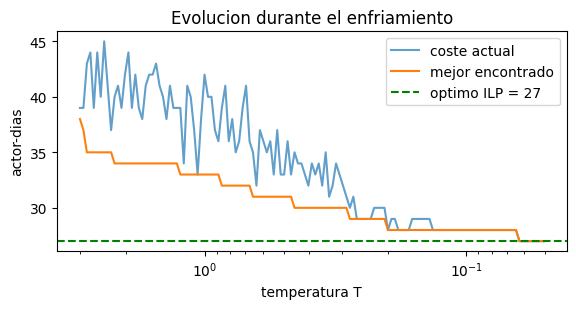

In [27]:
# ============================================================
# ROBUSTEZ DEL RECOCIDO SIMULADO: muchas semillas sobre el problema real
# ============================================================
import statistics
from collections import Counter
import matplotlib.pyplot as plt

N_SEMILLAS = 50
resultados = [recocido_simulado(tomas, seed=s)[1] for s in range(N_SEMILLAS)]
aciertos = resultados.count(opt_real)
print(f"{N_SEMILLAS} ejecuciones: minimo = {min(resultados)}, media = {statistics.mean(resultados):.2f}, maximo = {max(resultados)}")
print(f"Alcanzan el optimo del ILP ({opt_real}): {aciertos}/{N_SEMILLAS} = {100*aciertos/N_SEMILLAS:.0f} %")
print("Distribucion (coste: nº de ejecuciones):", dict(sorted(Counter(resultados).items())))

# Grafica: evolucion del coste durante el enfriamiento (una ejecucion)
_, _, hist = recocido_simulado(tomas, seed=0)
plt.figure(figsize=(6, 3.2))
plt.plot([h[0] for h in hist], [h[1] for h in hist], alpha=0.7, label="coste actual")
plt.plot([h[0] for h in hist], [h[2] for h in hist], label="mejor encontrado")
plt.axhline(opt_real, color="g", ls="--", label=f"optimo ILP = {opt_real}")
plt.xscale("log"); plt.gca().invert_xaxis()
plt.xlabel("temperatura T"); plt.ylabel("actor-dias"); plt.legend(); plt.title("Evolucion durante el enfriamiento")
plt.tight_layout(); plt.show()

### Enumera las referencias que has utilizado(si ha sido necesario) para llevar a cabo el trabajo

**Respuesta**

- Brassard, G. y Bratley, P. (1997). *Fundamentos de algoritmia*. Prentice Hall.
- Guerequeta, R. y Vallecillo, A. (2000). *Técnicas de diseño de algoritmos*. Universidad de Málaga.
- Duarte, A. (2008). *Metaheurísticas*. Madrid: Dykinson.
- Kirkpatrick, S., Gelatt, C. D. y Vecchi, M. P. (1983). *Optimization by Simulated Annealing*. Science, 220(4598), 671-680.
- Material y videoconferencias de la asignatura *Algoritmos de Optimización* (VIU).
- Números de Bell y particiones de conjuntos (conteo de posibilidades).
- PuLP con el solver CBC (COIN-OR): https://coin-or.github.io/pulp/

### Describe brevemente las lineas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño


**Respuesta**

- **Mejorar el algoritmo:** enfriamiento adaptativo o con recalentamientos, vecindarios más ricos (mover bloques de tomas), ajuste de T₀ y α sobre muchas instancias aleatorias, y comparar con otras metaheurísticas (búsqueda tabú, algoritmos genéticos, colonia de hormigas).
- **Métodos exactos más escalables:** mejores cotas para ramificación y poda, formulaciones ILP más ajustadas, solvers comerciales (Gurobi, CPLEX) o generación de columnas.
- **Tamaños mayores:** fuerza bruta, programación dinámica e ILP dejan de ser viables; el recocido simulado escala de forma lineal en el número de iteraciones y se puede paralelizar (varias semillas a la vez).
- **Variaciones del problema** (tarifa distinta por actor, precedencias entre tomas, otro límite de tomas por día): la estructura se mantiene; basta añadir restricciones (rechazar vecinos inválidos) o cambiar la función de coste.